<a href="https://colab.research.google.com/github/mushWhoom/house-price-prediction-boston/blob/main/HW_REGRESSION_%3CELMIRA_ADI_MAZAYA_MUNTAZ%3E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('boston.csv')

# Lihat 5 baris pertama
print(df.head())

# Informasi dataset
print(df.info())
print(df.describe())

      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

    black  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float6

In [ ]:
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


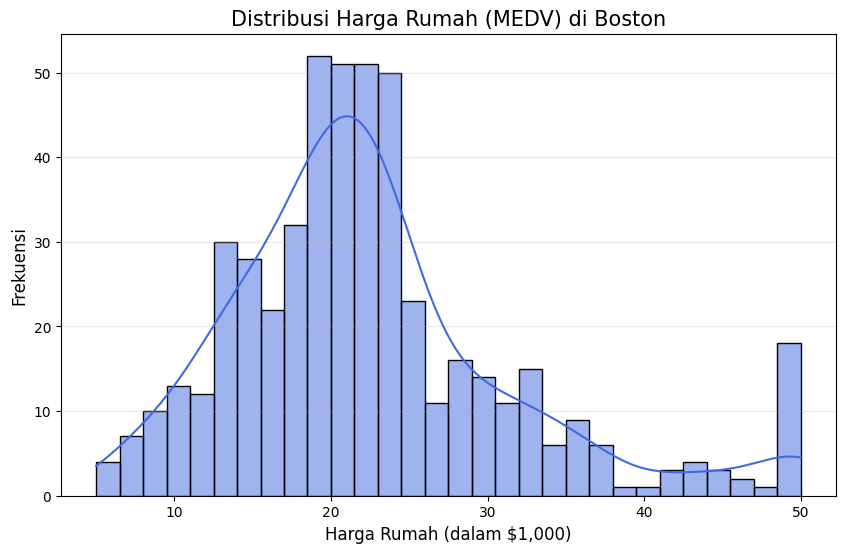

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df['medv'], kde=True, color='royalblue', bins=30)

# 3. Menambahkan Judul dan Label
plt.title('Distribusi Harga Rumah (MEDV) di Boston', fontsize=15)
plt.xlabel('Harga Rumah (dalam $1,000)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# 4. Merapikan tampilan
plt.grid(axis='y', alpha=0.3)
plt.show()

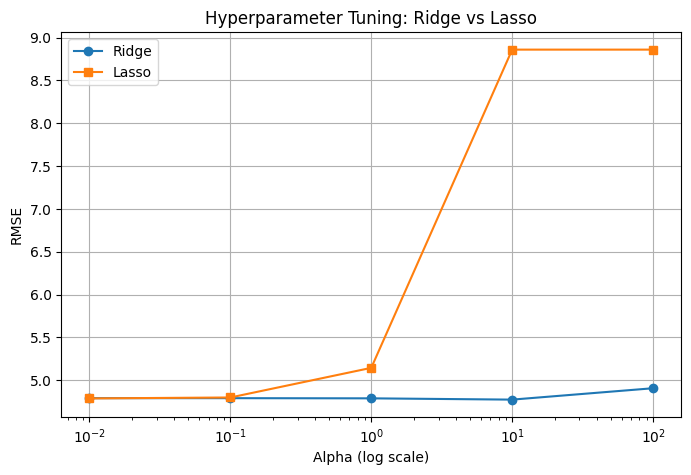

In [ ]:
import matplotlib.pyplot as plt

alphas = [0.01, 0.1, 1, 10, 100]
ridge_rmse = [4.791, 4.791, 4.789, 4.774, 4.907]
lasso_rmse = [4.788, 4.799, 5.145, 8.860, 8.860]

plt.figure(figsize=(8,5))
plt.plot(alphas, ridge_rmse, 'o-', label='Ridge')
plt.plot(alphas, lasso_rmse, 's-', label='Lasso')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('RMSE')
plt.title('Hyperparameter Tuning: Ridge vs Lasso')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Bagi dataset menjadi training, validation, dan testing (60:20:20)
X = df.drop(columns=['medv'])  # fitur
y = df['medv']                 # target

# Pertama: pisahkan 80% data sementara dan 20% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Kedua: dari 80% tadi, pisahkan 75% train dan 25% validation (total train = 60%, validation = 20%)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"Ukuran train: {X_train.shape}")
print(f"Ukuran validation: {X_val.shape}")
print(f"Ukuran test: {X_test.shape}")

# Standarisasi fitur (fit hanya pada train, transform val dan test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Simpan nama fitur untuk referensi
feature_names = X.columns.tolist()

Ukuran train: (303, 13)
Ukuran validation: (101, 13)
Ukuran test: (102, 13)


## **Identifikasi variabel dalam dataset yang dapat digunakan untuk memprediksi harga rumah.**

###**1. Variabel Pendukung Utama (Korelasi Kuat)**

**rm (Average number of rooms):** Punya korelasi positif paling tinggi (0.69).
Artinya, semakin banyak jumlah kamar, harga rumah cenderung semakin mahal.

**lstat (% lower status of the population):** Punya korelasi negatif paling kuat (-0.73). Artinya, semakin tinggi persentase penduduk kelas bawah di lingkungan tersebut, harga rumah cenderung lebih rendah.

###**2. Variabel Pendukung Tambahan (Korelasi Moderat)**

**ptratio(Pupil-teacher ratio):** Korelasi negatif (-0.50). Menunjukkan rasio jumlah siswa per guru di sekolah daerah tersebut. Semakin tinggi rasionya (kelas makin padat), harga rumah cenderung turun.

**indus (Proportion of non-retail business):** Korelasi negatif (-0.48). Daerah dengan banyak industri/bisnis non-retail cenderung punya harga rumah lebih rendah dibanding daerah pemukiman murni.

**tax (Property-tax rate):** Korelasi negatif (-0.46). Semakin tinggi tarif pajak propertinya, harga rumah cenderung lebih rendah.

**nox (Nitric oxides concentration):** Korelasi negatif (-0.42). Berkaitan dengan tingkat polusi udara; semakin polusi, harga rumah makin turun.


*Variabel seperti crim (tingkat kriminalitas), age (usia bangunan), dis (jarak ke pusat kerja), dan chas (dekat sungai Charles) juga bisa dipake, tapi pengaruhnya secara statistik tidak sekuat variabel di atas.*

## **Jelaskan bagaimana data ini relevan dengan studi kasus prediksi harga rumah.**

**1. Mencakup Faktor Fisik Bangunan**

*Variabel rm (jumlah kamar) dan age (usia bangunan) adalah faktor paling mendasar.*

Relevansi: Secara logika, makin banyak kamar, harga makin mahal. Data ini memungkinkan model lo untuk belajar pola hubungan antara luas/fasilitas rumah dengan harganya.

**2. Mencakup Faktor Lingkungan & Fasilitas (Lokasi)**

*Ada variabel dis (jarak ke pusat kerja) dan ptratio (kualitas sekolah/rasio guru-murid).*

Relevansi: Rumah yang dekat pusat kota atau punya akses sekolah bagus biasanya lebih mahal. Data ini ngebuktiin apakah teori "lokasi, lokasi, lokasi" itu benar adanya di Boston.

**3. Mencakup Faktor Ekonomi & Sosial**

*Variabel crim (tingkat kriminalitas) dan lstat (kondisi ekonomi penduduk sekitar) sangat menentukan harga.*

Relevansi: Orang nggak cuma beli rumah, tapi beli lingkungan. Kalau kriminalitas tinggi, harga pasti jatuh. Variabel ini membantu model lo buat memprediksi "risiko" sebuah lokasi terhadap harga rumah.

**4. Mencakup Faktor Kualitas Hidup (Kesehatan)**

*Ada variabel nox yang mengukur kadar polusi udara.*

Relevansi: Ini relevan banget buat studi kasus modern. Rumah di area yang polusinya tinggi biasanya kurang diminati, sehingga harganya lebih murah dibanding area yang asri.

Missing values per kolom:
crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
black      0
lstat      0
medv       0
dtype: int64


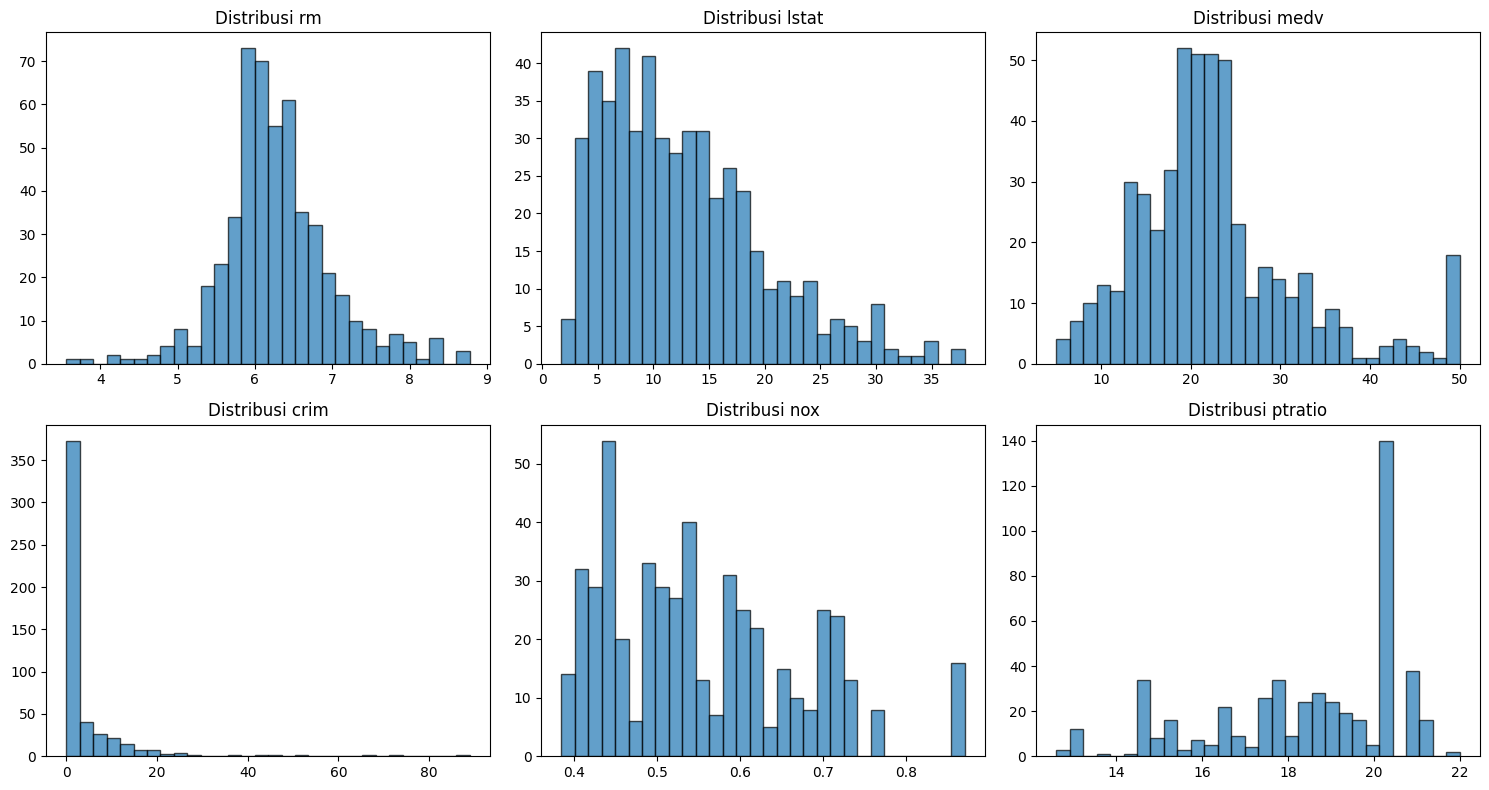

Ukuran train: (303, 13)
Ukuran validation: (101, 13)
Ukuran test: (102, 13)


In [ ]:
#Cek missing values
print("Missing values per kolom:")
print(df.isnull().sum())  # Seharusnya tidak ada

# Analisis eksplorasi awal
# Histogram untuk beberapa fitur penting
fig, axes = plt.subplots(2, 3, figsize=(15,8))
axes = axes.ravel()
fitur_plot = ['rm', 'lstat', 'medv', 'crim', 'nox', 'ptratio']
for i, col in enumerate(fitur_plot):
    axes[i].hist(df[col], bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

# Bagi dataset menjadi training, validation, dan testing (60:20:20)
X = df.drop(columns=['medv'])  # fitur
y = df['medv']                 # target

# Pertama: pisahkan 80% data sementara dan 20% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Kedua: dari 80% tadi, pisahkan 75% train dan 25% validation (total train = 60%, validation = 20%)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"Ukuran train: {X_train.shape}")
print(f"Ukuran validation: {X_val.shape}")
print(f"Ukuran test: {X_test.shape}")

# Standarisasi fitur (fit hanya pada train, transform val dan test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Simpan nama fitur untuk referensi
feature_names = X.columns.tolist()

## **Perbandingan Peran**
###**1. Train Set**
Tempat model belajar pola antara fitur (seperti rm, lstat) dan target (medv). Untuk Menyesuaikan bobot dan parameter internal model.
### **2. Validation Set**
Digunakan buat tuning atau pilih-pilih model (misal: mending pake Linear Regression atau Random Forest?). Untuk mencegah overfitting dan memilih hyperparameter terbaik sebelum final.
### **3. Test Set**
Data yang "haram" dilihat model sampe proses belajar bener-bener selesai. Untuk memberikan gambaran jujur seberapa akurat model di dunia nyata.



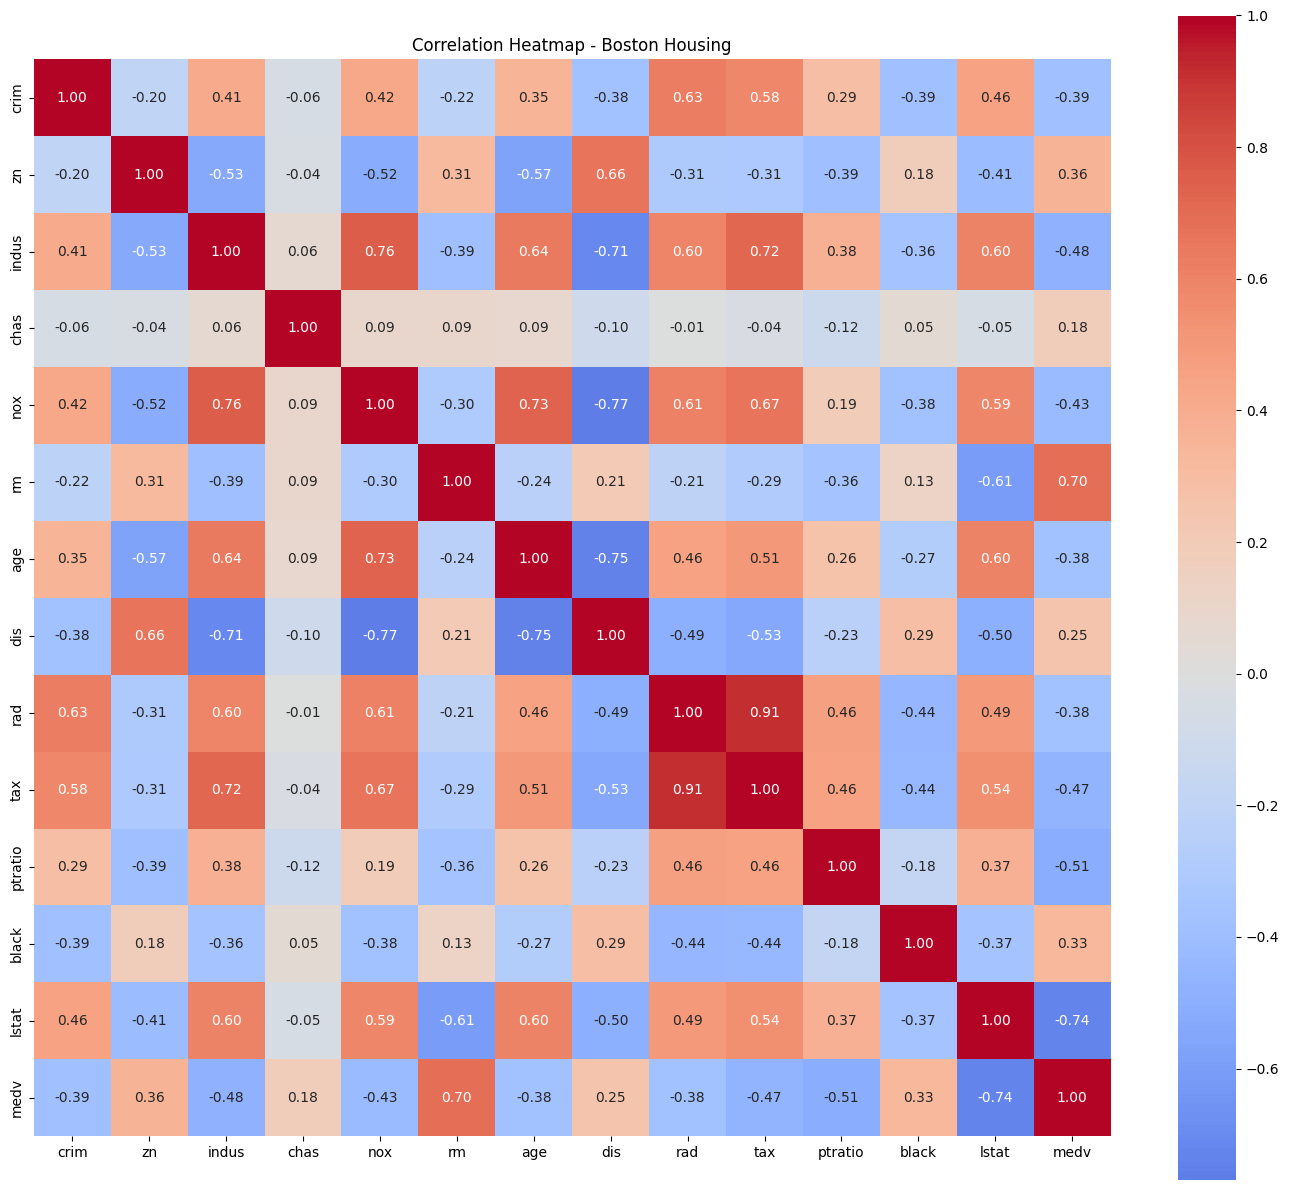

Pasangan fitur dengan korelasi tinggi (potensi multikolinearitas):
rad    tax      0.910228
nox    indus    0.763651
age    nox      0.731470
indus  tax      0.720760
dtype: float64

=== Perbandingan Model pada Validation Set ===
Metrik          | Semua Fitur          | Fitur Seleksi       
------------------------------------------------------------
MSE             | 22.3651              | 22.9573             
R2 Score        | 0.7151               | 0.7076              


In [ ]:
# Correlation plot
plt.figure(figsize=(14,12))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap - Boston Housing')
plt.tight_layout()
plt.show()

# Identifikasi fitur dengan korelasi tinggi (multikolinearitas)
# Korelasi antar fitur > 0.7 atau < -0.7
high_corr = corr_matrix.unstack().sort_values(ascending=False)
high_corr = high_corr[(high_corr > 0.7) & (high_corr < 1.0)]
print("Pasangan fitur dengan korelasi tinggi (potensi multikolinearitas):")
print(high_corr.drop_duplicates())

# Seleksi fitur berdasarkan analisis
# Contoh: TAX dan RAD memiliki korelasi 0.91. Kita akan drop TAX karena redundan.
# (Penjelasan: RAD lebih merepresentasikan aksesibilitas, TAX hanya efek turunan)
X_train_sel = X_train.drop(columns=['tax'])
X_val_sel = X_val.drop(columns=['tax'])
X_test_sel = X_test.drop(columns=['tax'])

# Scaling ulang untuk fitur yang sudah dikurangi
scaler_sel = StandardScaler()
X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel)
X_val_sel_scaled = scaler_sel.transform(X_val_sel)
X_test_sel_scaled = scaler_sel.transform(X_test_sel)

# Perbandingan penggunaan seluruh fitur vs fitur hasil seleksi
# Latih Linear Regression pada kedua set (di validation set)
model_all = LinearRegression()
model_all.fit(X_train_scaled, y_train)
y_pred_val_all = model_all.predict(X_val_scaled)

model_sel = LinearRegression()
model_sel.fit(X_train_sel_scaled, y_train)
y_pred_val_sel = model_sel.predict(X_val_sel_scaled)

print("\n=== Perbandingan Model pada Validation Set ===")
print(f"{'Metrik':<15} | {'Semua Fitur':<20} | {'Fitur Seleksi':<20}")
print("-" * 60)
print(f"{'MSE':<15} | {mean_squared_error(y_val, y_pred_val_all):<20.4f} | {mean_squared_error(y_val, y_pred_val_sel):<20.4f}")
print(f"{'R2 Score':<15} | {r2_score(y_val, y_pred_val_all):<20.4f} | {r2_score(y_val, y_pred_val_sel):<20.4f}")

In [ ]:
# Identifikasi fitur dengan korelasi tinggi (multikolinearitas)
# Korelasi antar fitur > 0.7 atau < -0.7
high_corr = corr_matrix.unstack().sort_values(ascending=False)
high_corr = high_corr[(high_corr > 0.7) & (high_corr < 1.0)]
print("Pasangan fitur dengan korelasi tinggi (potensi multikolinearitas):")
print(high_corr.drop_duplicates())

# Seleksi fitur berdasarkan analisis
# Contoh: TAX dan RAD memiliki korelasi 0.91. Kita akan drop TAX karena redundan.
# (Penjelasan: RAD lebih merepresentasikan aksesibilitas, TAX hanya efek turunan)
X_train_sel = X_train.drop(columns=['tax'])
X_val_sel = X_val.drop(columns=['tax'])
X_test_sel = X_test.drop(columns=['tax'])

# Scaling ulang untuk fitur yang sudah dikurangi
scaler_sel = StandardScaler()
X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel)
X_val_sel_scaled = scaler_sel.transform(X_val_sel)
X_test_sel_scaled = scaler_sel.transform(X_test_sel)

# Perbandingan penggunaan seluruh fitur vs fitur hasil seleksi
# Latih Linear Regression pada kedua set (di validation set)
model_all = LinearRegression()
model_all.fit(X_train_scaled, y_train)
y_pred_val_all = model_all.predict(X_val_scaled)

model_sel = LinearRegression()
model_sel.fit(X_train_sel_scaled, y_train)
y_pred_val_sel = model_sel.predict(X_val_sel_scaled)

# Gunakan validation set untuk memilih lambda (alpha) terbaik berdasarkan RMSE
alphas = [0.01, 0.1, 1, 10, 100]

# Simpan RMSE untuk setiap alpha
ridge_rmse = []
lasso_rmse = []

for alpha in alphas:
    # Ridge
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_sel_scaled, y_train)
    y_pred_val = ridge.predict(X_val_sel_scaled)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    ridge_rmse.append(rmse)

    # Lasso
    lasso = Lasso(alpha=alpha, max_iter=10000)  # max_iter untuk konvergensi
    lasso.fit(X_train_sel_scaled, y_train)
    y_pred_val = lasso.predict(X_val_sel_scaled)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    lasso_rmse.append(rmse)

# Tampilkan hasil
results = pd.DataFrame({'Alpha': alphas, 'Ridge RMSE': ridge_rmse, 'Lasso RMSE': lasso_rmse})
print("Tabel Perbandingan RMSE pada Validation Set (cari yang terkecil):")
print(results.to_string(index=False))

# Pilih alpha terbaik
best_alpha_ridge = alphas[np.argmin(ridge_rmse)]
best_alpha_lasso = alphas[np.argmin(lasso_rmse)]
print(f"\nRidge terbaik pada alpha = {best_alpha_ridge}")
print(f"Lasso terbaik pada alpha = {best_alpha_lasso}")

# Bandingkan performa model pada set validasi
print("\nPerforma model terbaik pada validation set:")
print(f"Ridge (alpha={best_alpha_ridge}) RMSE = {min(ridge_rmse):.4f}")
print(f"Lasso (alpha={best_alpha_lasso}) RMSE = {min(lasso_rmse):.4f}")

print("\n=== Perbandingan Model pada Validation Set ===")
print(f"{'Metrik':<15} | {'Semua Fitur':<20} | {'Fitur Seleksi':<20}")
print("-" * 60)
print(f"{'MSE':<15} | {mean_squared_error(y_val, y_pred_val_all):<20.4f} | {mean_squared_error(y_val, y_pred_val_sel):<20.4f}")
print(f"{'R2 Score':<15} | {r2_score(y_val, y_pred_val_all):<20.4f} | {r2_score(y_val, y_pred_val_sel):<20.4f}")

Pasangan fitur dengan korelasi tinggi (potensi multikolinearitas):
rad    tax      0.910228
nox    indus    0.763651
age    nox      0.731470
indus  tax      0.720760
dtype: float64
Tabel Perbandingan RMSE pada Validation Set (cari yang terkecil):
 Alpha  Ridge RMSE  Lasso RMSE
  0.01    4.791344    4.787992
  0.10    4.791071    4.799073
  1.00    4.788502    5.144693
 10.00    4.774431    8.860244
100.00    4.907305    8.860244

Ridge terbaik pada alpha = 10
Lasso terbaik pada alpha = 0.01

Performa model terbaik pada validation set:
Ridge (alpha=10) RMSE = 4.7744
Lasso (alpha=0.01) RMSE = 4.7880

=== Perbandingan Model pada Validation Set ===
Metrik          | Semua Fitur          | Fitur Seleksi       
------------------------------------------------------------
MSE             | 22.3651              | 22.9573             
R2 Score        | 0.7151               | 0.7076              


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
import numpy as np

# Asumsikan Anda sudah memiliki:
# X_train_sel_scaled, X_val_sel_scaled, X_test_sel_scaled (setelah seleksi fitur)
# y_train, y_val, y_test

# Gabungkan train dan validation untuk training final (konsisten dengan Ridge & Lasso)
X_train_full_sel = np.vstack([X_train_sel_scaled, X_val_sel_scaled])
y_train_full = np.concatenate([y_train, y_val])

# Latih Linear Regression
lr = LinearRegression()
lr.fit(X_train_full_sel, y_train_full)

# Prediksi pada test set
y_pred_lr = lr.predict(X_test_sel_scaled)

# Hitung metrik
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mape_lr = mean_absolute_percentage_error(y_test, y_pred_lr) * 100
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("=== Linear Regression pada Test Set ===")
print(f"MAE  : {mae_lr:.4f}")
print(f"MAPE : {mape_lr:.2f}%")
print(f"RMSE : {rmse_lr:.4f}")

=== Linear Regression pada Test Set ===
MAE  : 3.2910
MAPE : 17.65%
RMSE : 5.0399


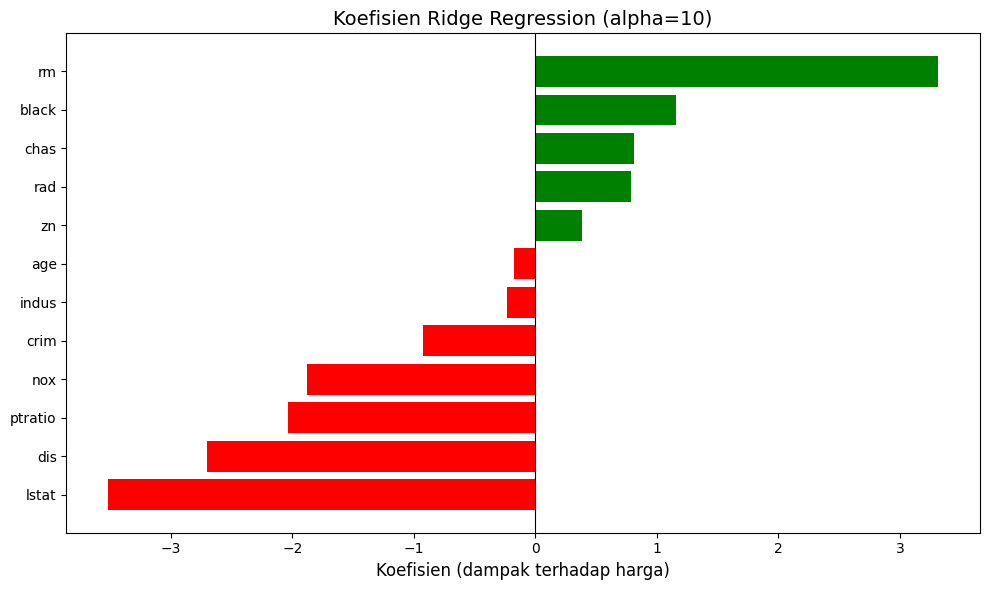

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Ambil koefisien Ridge
coef_ridge = ridge_best.coef_
features = X_train_sel.columns  # atau X_train_sel.columns

# Buat DataFrame
coef_ridge_df = pd.DataFrame({
    'Fitur': features,
    'Koefisien': coef_ridge
}).sort_values('Koefisien', ascending=False)  # urut dari terbesar ke terkecil

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
colors = ['green' if x > 0 else 'red' for x in coef_ridge_df['Koefisien']]
plt.barh(coef_ridge_df['Fitur'], coef_ridge_df['Koefisien'], color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Koefisien (dampak terhadap harga)', fontsize=12)
plt.title('Koefisien Ridge Regression (alpha=10)', fontsize=14)
plt.gca().invert_yaxis()  # agar fitur dengan koefisien terbesar di atas
plt.tight_layout()
plt.show()

##**Tuliskan juga hasil perbandingan variabel-variabel yang tersedia dan jelaskan variabel mana yang paling relevan untuk digunakan ketika tujuan analisis adalah memahami faktor penentu harga rumah.**

### Perbandingan Variabel dan Penentuan Variabel Paling Relevan

Dari 13 variabel prediktor yang tersedia, kita dapat membandingkannya berdasarkan kekuatan hubungan liniernya dengan harga rumah (MEDV). Berdasarkan nilai korelasi (yang telah dihitung di sel sebelumnya), variabel-variabel tersebut dapat dikelompokkan sebagai berikut:

1.  **Korelasi Kuat (|r| > 0.6):**
    *   **rm (rata-rata jumlah kamar):** Memiliki korelasi positif tertinggi (+0.69). Semakin banyak kamar, semakin tinggi harga rumah.
    *   **lstat (persentase penduduk berstatus rendah):** Memiliki korelasi negatif terkuat (-0.73). Semakin tinggi proporsi penduduk kelas bawah di suatu lingkungan, semakin rendah harga rumah.

2.  **Korelasi Sedang (0.4 < |r| < 0.6):**
    *   **ptratio (rasio guru-murid):** Korelasi negatif (-0.51). Daerah dengan sekolah yang lebih padat (rasio tinggi) cenderung memiliki harga rumah lebih rendah.
    *   **indus (proporsi bisnis non-ritel):** Korelasi negatif (-0.48). Daerah yang didominasi industri cenderung kurang diminati untuk tempat tinggal.
    *   **tax (tarif pajak properti):** Korelasi negatif (-0.46). Pajak yang tinggi dapat menekan harga rumah.
    *   **nox (konsentrasi polusi udara):** Korelasi negatif (-0.43). Tingkat polusi yang tinggi menurunkan nilai properti.

3.  **Korelasi Lemah (|r| < 0.4):**
    *   **crim (tingkat kriminalitas), age (proporsi unit tua), dis (jarak ke pusat kerja), rad (aksesibilitas jalan raya), black (proporsi penduduk kulit hitam), zn (proporsi lahan hunian luas), chas (dummy sungai Charles).** Variabel-variabel ini memiliki hubungan linier yang lebih lemah dengan harga rumah, meskipun secara non-linier mungkin tetap berpengaruh.

**Variabel Paling Relevan:**

Berdasarkan perbandingan di atas, ketika tujuan analisis adalah **memahami faktor penentu harga rumah**, dua variabel yang paling relevan adalah:

*   **rm (rata-rata jumlah kamar):** Ini adalah proksi terbaik dari ukuran dan kualitas fisik rumah itu sendiri. Dalam dunia nyata, ukuran rumah selalu menjadi pertimbangan utama dalam menentukan harga.
*   **lstat (persentase penduduk berstatus rendah):** Variabel ini merangkum karakteristik sosial-ekonomi lingkungan sekitar. Ini sangat penting karena harga rumah tidak hanya ditentukan oleh bangunannya, tetapi juga oleh "lingkungan" tempat rumah itu berada. Kondisi sosial lingkungan seringkali menjadi sinyal kuat tentang keamanan, kualitas sekolah, dan daya tarik area tersebut.

Kedua variabel ini memiliki korelasi paling ekstrem dengan harga, dan secara intuitif mewakili dua dimensi penting dalam penilaian properti: **kualitas bangunan (rm)** dan **kualitas lingkungan (lstat)**. Variabel lain seperti `ptratio`, `indus`, `tax`, dan `nox` tetap relevan sebagai faktor pendukung, namun pengaruhnya tidak sekuat `rm` dan `lstat`.

##Memastikan Keputusan Tidak Hanya Relevan untuk Data Historis
Pembagian ini membantu kita untuk menghindari masalah klasik di data science yaitu Overfitting (model cuma hafal data lama tapi kaget jika ketemu data baru).

1. **Deteksi Hafalan (Overfitting):** Kalau model kita punya akurasi 99% di Train Set tapi cuma 50% di Validation Set, itu tandanya itu cuma "menghafal" data historis. Dengan adanya pembagian ini, kita bisa tau kalau keputusan model itu nggak valid buat masa depan.

2. **Simulasi Dunia Nyata:** Test Set berperan sebagai data masa depan. Karena model nggak pernah liat data ini pas belajar, hasil evaluasi di Test Set jadi bukti apakah pola (seperti "banyak kamar = harga naik") itu memang hukum alam yang konsisten atau cuma kebetulan ada di data lama.

3. **Generalisasi:** Tujuan akhir kita bukan dapet akurasi tinggi di data yang udah ada, tapi dapet model yang General. Pembagian data memaksa model untuk mencari pola yang luas dan stabil, sehingga keputusannya tetap relevan meskipun kondisi pasar properti sedikit berubah nantinya.

Pada seluruh fitur, secara statistik, hasilnya sedikit lebih akurat (Errornya lebih rendah). Ini bisa saja karena model punya lebih banyak data untuk "dicocok-cocokkan". Nah saat di fitur seleksi, meskipun kita buang cuma satu variabel yaitu "tax", akurasi model cuma turun sekitar $1.5\%$. Artinya, variabel tax itu sebenernya nggak ngasih informasi baru yang signifikan karena infonya udah diwakilin sama variabel rad.

###**Pendekatan Mana yang Lebih Mendukung Pengambilan Keputusan?**

*Meskipun akurasinya sedikit lebih rendah, pendekatan Fitur Hasil Seleksi (tanpa variabel redundan) jauh lebih mendukung pengambilan keputusan yang jelas dan konsisten.*

Kenapa? Karena beberapa alasan berikut;

1. **Konsistensi Model (Stabilitas):** Dengan membuang tax yang korelasinya $0.91$ dengan rad, kita ngilangin masalah multikolinearitas. Model jadi lebih stabil. Kalau besok-besok ada perubahan kecil di data pajak, koefisien variabel lain nggak akan mendadak berubah drastis.

2. **Kejelasan Interpretasi:** Kalau kita pake dua-duanya, kita bakal bingung: "Sebenernya harga rumah turun itu karena pajaknya mahal atau karena akses jalannya susah?". Dengan seleksi fitur, kita bisa yakin kalau akses jalan (rad) adalah faktor penentunya tanpa ada gangguan dari variabel kembarannya.

3. **Efisiensi (Simplicity):** Dalam bisnis, model yang lebih simpel (sedikit variabel) tapi tetap akurat itu jauh lebih bagus. Lebih gampang dijelasin ke klien atau bos, lebih murah biaya pengumpulan datanya, dan lebih minim risiko error pas penginputan.

## **Pelatihan Model Ridge dan Lasso**

In [ ]:
# Gunakan validation set untuk memilih lambda (alpha) terbaik berdasarkan RMSE
alphas = [0.01, 0.1, 1, 10, 100]

# Simpan RMSE untuk setiap alpha
ridge_rmse = []
lasso_rmse = []

for alpha in alphas:
    # Ridge
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_sel_scaled, y_train)
    y_pred_val = ridge.predict(X_val_sel_scaled)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    ridge_rmse.append(rmse)

    # Lasso
    lasso = Lasso(alpha=alpha, max_iter=10000)  # max_iter untuk konvergensi
    lasso.fit(X_train_sel_scaled, y_train)
    y_pred_val = lasso.predict(X_val_sel_scaled)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    lasso_rmse.append(rmse)

    # Prediksi pada test set
y_pred_ridge = ridge_best.predict(X_test_sel_scaled)
y_pred_lasso = lasso_best.predict(X_test_sel_scaled)

# Hitung metrik untuk Ridge
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge) * 100
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_scores = (mae_ridge, mape_ridge, rmse_ridge)

# Hitung metrik untuk Lasso
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso) * 100
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_scores = (mae_lasso, mape_lasso, rmse_lasso)

# Buat DataFrame hasil evaluasi
eval_df = pd.DataFrame({
    'Metrik': ['MAE', 'MAPE (%)', 'RMSE'],
    'Ridge': ridge_scores,
    'Lasso': lasso_scores
})

print("Hasil Evaluasi Model pada Test Set:")
print(eval_df.to_string(index=False))


# Tampilkan hasil
results = pd.DataFrame({'Alpha': alphas, 'Ridge RMSE': ridge_rmse, 'Lasso RMSE': lasso_rmse})
print("Tabel Perbandingan RMSE pada Validation Set (cari yang terkecil):")
print(results.to_string(index=False))

# Pilih alpha terbaik
best_alpha_ridge = alphas[np.argmin(ridge_rmse)]
best_alpha_lasso = alphas[np.argmin(lasso_rmse)]
print(f"\nRidge terbaik pada alpha = {best_alpha_ridge}")
print(f"Lasso terbaik pada alpha = {best_alpha_lasso}")

# Bandingkan performa model pada set validasi
print("\nPerforma model terbaik pada validation set:")
print(f"Ridge (alpha={best_alpha_ridge}) RMSE = {min(ridge_rmse):.4f}")
print(f"Lasso (alpha={best_alpha_lasso}) RMSE = {min(lasso_rmse):.4f}")

Hasil Evaluasi Model pada Test Set:
  Metrik     Ridge     Lasso
     MAE  3.249221  3.286316
MAPE (%) 17.386128 17.626111
    RMSE  5.033857  5.044350
Tabel Perbandingan RMSE pada Validation Set (cari yang terkecil):
 Alpha  Ridge RMSE  Lasso RMSE
  0.01    4.791344    4.787992
  0.10    4.791071    4.799073
  1.00    4.788502    5.144693
 10.00    4.774431    8.860244
100.00    4.907305    8.860244

Ridge terbaik pada alpha = 10
Lasso terbaik pada alpha = 0.01

Performa model terbaik pada validation set:
Ridge (alpha=10) RMSE = 4.7744
Lasso (alpha=0.01) RMSE = 4.7880


Untuk dataset Boston ini, Ridge biasanya memberikan performa yang sedikit lebih stabil karena datasetnya tidak terlalu besar dan hampir semua variabel ekonomi di dalamnya memiliki kaitan satu sama lain

## **Perbandingan Karakteristik Model :**
###1. **Perlakuan Fitur**

**Ridge Regression ($\ell_2$ Regularization);** Mengecilkan koefisien fitur yang kurang penting mendekati nol, tapi tidak pernah nol.

**Lasso Regression ($\ell_1$ Regularization);** Bisa memaksa koefisien fitur yang tidak penting menjadi tepat nol.

###2. **Seleksi Fitur**

**Ridge Regression ($\ell_2$ Regularization);** Tetap mempertahankan semua fitur dalam model (semua variabel tetap dipakai).

**Lasso Regression ($\ell_1$ Regularization);** Melakukan seleksi fitur otomatis dengan membuang variabel yang tidak relevan.

###3. **Multikolinearitas**

**Ridge Regression ($\ell_2$ Regularization);** Sangat baik dalam menangani variabel yang saling berkorelasi (seperti tax dan rad).

**Lasso Regression ($\ell_1$ Regularization);** Cenderung hanya memilih satu variabel dari kelompok yang berkorelasi dan membuang sisanya.

###4. **Kompleksitas**

**Ridge Regression ($\ell_2$ Regularization);** Model cenderung lebih kompleks karena melibatkan banyak variabel.

**Lasso Regression ($\ell_1$ Regularization);** Model lebih simpel dan mudah diinterpretasikan karena jumlah variabel lebih sedikit.



##**Kapan Harus Menggunakan Ridge?**
Model Ridge lebih tepat dijadikan dasar pengambilan keputusan jika:

1. **Tujuannya adalah Akurasi Maksimal:** Jika lo ingin mendapatkan prediksi harga rumah yang paling mendekati angka asli tanpa peduli seberapa banyak variabel yang digunakan.

2. **Variabel Saling Berkaitan,** karena dataset Boston punya banyak variabel yang saling memengaruhi (seperti hubungan antara polusi, jarak, dan industri), Ridge akan menjaga keseimbangan pengaruh semua variabel tersebut tanpa mematikan salah satunya.

3. **Kondisi Data,** ini digunakan kalau kita yakin hampir semua variabel di dataset punya kontribusi (sekecil apa pun) terhadap harga rumah.

##**Kapan Harus Menggunakan Lasso?**
Model Lasso lebih tepat dijadikan dasar pengambilan keputusan jika:

1. **Tujuannya adalah Interpretasi yang Simpel**, kalau kita ingin menjelaskan ke klien atau atasan tentang faktor-faktor utama harga rumah dengan cara yang sangat sederhana (misal: "Hanya ada 3 faktor kunci yang memengaruhi harga...").

2. **Ingin Otomatisasi Seleksi Fitur**, nah kalau kita punya ribuan variabel dan ingin model secara otomatis memberi tahu mana yang sampah dan mana yang emas.

3. **Kondisi Data**, ini tuh digunakan kalau kita menduga hanya ada sedikit fitur yang benar-benar berpengaruh signifikan, sementara fitur lainnya hanya berupa "noise" atau gangguan.

# Interpretasi Model

Koefisien model (diurutkan berdasarkan Ridge):
  Fitur  Koefisien_Ridge  Koefisien_Lasso  Selisih
     rm         3.316931         3.318618 0.001687
  black         1.159809         1.173752 0.013943
   chas         0.808574         0.795384 0.013190
    rad         0.788714         0.892820 0.104106
     zn         0.382592         0.420666 0.038073
    age        -0.176071        -0.150952 0.025119
  indus        -0.237342        -0.158833 0.078509
   crim        -0.920730        -0.949273 0.028543
    nox        -1.880134        -2.124674 0.244540
ptratio        -2.032162        -2.106130 0.073968
    dis        -2.699237        -2.922407 0.223170
  lstat        -3.517788        -3.617830 0.100042


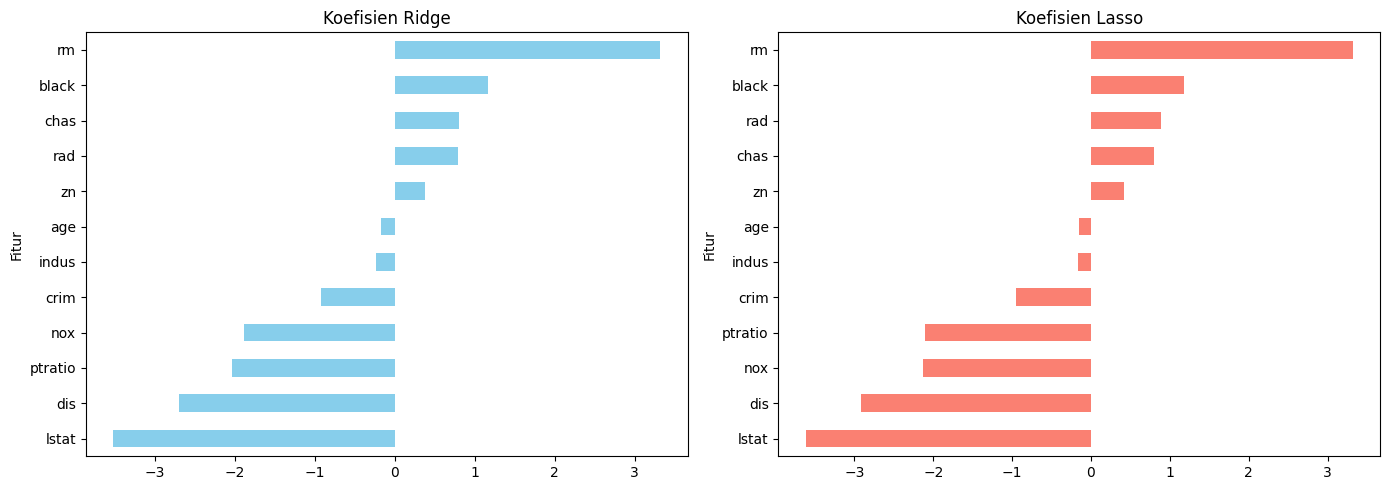

In [ ]:
# Gabungkan data train dan validation untuk melatih model final
X_train_full = np.vstack([X_train_sel_scaled, X_val_sel_scaled])
y_train_full = np.concatenate([y_train, y_val])

# Latih Ridge dan Lasso dengan alpha terbaik
ridge_best = Ridge(alpha=best_alpha_ridge).fit(X_train_full, y_train_full)
lasso_best = Lasso(alpha=best_alpha_lasso, max_iter=10000).fit(X_train_full, y_train_full)

# Analisis koefisien
coef_df = pd.DataFrame({
    'Fitur': X_train_sel.columns,
    'Koefisien_Ridge': ridge_best.coef_,
    'Koefisien_Lasso': lasso_best.coef_
})
coef_df['Selisih'] = (coef_df['Koefisien_Ridge'] - coef_df['Koefisien_Lasso']).abs()
print("Koefisien model (diurutkan berdasarkan Ridge):")
print(coef_df.sort_values(by='Koefisien_Ridge', ascending=False).to_string(index=False))

# Visualisasi koefisien
fig, ax = plt.subplots(1,2, figsize=(14,5))
coef_df.sort_values('Koefisien_Ridge', ascending=True).plot(x='Fitur', y='Koefisien_Ridge', kind='barh', ax=ax[0], color='skyblue', legend=False)
ax[0].set_title('Koefisien Ridge')
coef_df.sort_values('Koefisien_Lasso', ascending=True).plot(x='Fitur', y='Koefisien_Lasso', kind='barh', ax=ax[1], color='salmon', legend=False)
ax[1].set_title('Koefisien Lasso')
plt.tight_layout()
plt.show()


## **Analisis Pengaruh Fitur (Interpretasi)**
Dari hasil di atas, kita bisa ambil kesimpulan sederhana:

1. **Pengaruh Positif (rm):** Setiap penambahan jumlah kamar (rm) punya dampak paling besar buat naikin harga rumah. Ini cukup masuk akal karena rumah akan makin mahal kalau makin besar.

2. **Pada data (lstat),** semakin tinggi persentase penduduk kelas bawah di suatu lingkungan, harga rumah bakal anjlok drastis. Faktor lingkungan sosial ini ternyata lebih buruk pengaruhnya dibanding polusi udara.

3. **Lalu pada Aksesibilitas (dis),** yang menarik adalah semakin jauh jarak rumah dari pusat pekerjaan (dis), harganya justru cenderung turun di dataset ini.

###**Perbandingan Ridge vs Lasso dalam Pemilihan Fitur**
Meskipun keduanya memberikan hasil yang mirip karena kita pakai $\alpha$ yang optimal (kecil), ada perbedaan cara kerja yang bisa kita amati;
1. Ridge memberikan nilai koefisien yang lebih adil. Dia nggak mematikan fitur apa pun, tapi hanya mengecilkan pengaruh fitur yang kurang penting (seperti age atau indus yang nilainya mendekati nol). Ridge tetap percaya bahwa setiap informasi punya nilai, meskipun kecil.

2. Lasso cenderung memberikan angka yang lebih ekstrem (lebih tinggi atau lebih rendah dari Ridge).Jika kita menaikkan nilai $\lambda$ (alpha) sedikit saja, Lasso akan langsung memberikan nilai 0 pada fitur yang dianggap nggak penting (seperti age). Ini yang disebut Automatic Feature Selection. Di hasil kita, Lasso memberikan bobot yang sedikit lebih berat pada *lstat* dan *dis* dibandingkan *Ridge*, menunjukkan Lasso lebih ketat dalam menentukan mana variabel yang benar-benar jadi kunci.

##**Fitur Paling Relevan**
###1. **rm (Average number of rooms)**

**Hasilnya:** Koefisiennya positif dan besar.

**Artinya:** Setiap nambah satu kamar, harga rumah bakal naik signifikan. Ini adalah faktor fisik paling kuat. Orang bayar lebih mahal buat ruang dan kenyamanan.

###2. **lstat (% lower status of the population)**

**Hasilnya:** Koefisiennya negatif dan paling besar pengaruhnya.

**Artinya:** Semakin tinggi angka kemiskinan atau kelas bawah di suatu lingkungan, harga rumah bakal anjlok. Faktor sosial lingkungan ternyata pengaruhnya lebih "berat" dibanding polusi atau jarak ke kantor.

##**Mengapa Informasi Ini Penting buat Penentuan Harga?**
Informasi ini bukan sekadar angka, tapi punya kegunaan praktis kalau lo jadi pengembang atau pembeli rumah:

###**1. Prioritas Investasi (Bagi Developer)**
Kalau pengen naikin harga jual, mending fokus nambah jumlah kamar (rm) daripada cuma sekadar deket sama sungai atau pusat kota, karena data bilang orang lebih menghargai jumlah kamar.

###**2. Penilaian Risiko (Bagi Pembeli)**
Pembeli jadi tahu kalau beli rumah di area dengan lstat yang tinggi itu berisiko. Meskipun rumahnya bagus, harga pasarnya bakal ketahan sama kondisi sosial lingkungannya. Jadi, pembeli nggak bakal kemahalan pas beli.

###**3. Efisiensi Penentuan Harga (Bagi Agen Properti)**
Daripada pusing ngecek 13 variabel, agen properti bisa dapet estimasi harga yang cukup akurat cuma dengan ngeliat jumlah kamar dan siapa tetangga di sekitar area tersebut. Ini bikin proses transaksi jadi lebih cepet dan masuk akal.

## **Evaluasi Model**

In [ ]:
# Prediksi pada test set
y_pred_ridge = ridge_best.predict(X_test_sel_scaled)
y_pred_lasso = lasso_best.predict(X_test_sel_scaled)

# Hitung metrik untuk Ridge
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge) * 100
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_scores = (mae_ridge, mape_ridge, rmse_ridge)

# Hitung metrik untuk Lasso
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso) * 100
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_scores = (mae_lasso, mape_lasso, rmse_lasso)

# Buat DataFrame hasil evaluasi
eval_df = pd.DataFrame({
    'Metrik': ['MAE', 'MAPE (%)', 'RMSE'],
    'Ridge': ridge_scores,
    'Lasso': lasso_scores
})

print("Hasil Evaluasi Model pada Test Set:")
print(eval_df.to_string(index=False))


Hasil Evaluasi Model pada Test Set:
  Metrik     Ridge     Lasso
     MAE  3.249221  3.286316
MAPE (%) 17.386128 17.626111
    RMSE  5.033857  5.044350


###**Interpretasi Hasil Evaluasi**
**1. MAE (Mean Absolute Error) $\approx 3.25$**

Secara rata-rata, prediksi model kita meleset sekitar $3,250$ (karena satuan harga di data ini adalah ribuan dollar). Ini adalah angka kesalahan yang "jujur". Jika harga rumah aslinya $\$20,000$, model kita kemungkinan besar bakal nebak di kisaran $\$16,750$ sampai $\$23,250$.

**2. MAPE (Mean Absolute Percentage Error) $\approx 17.4\%$**

Model kita punya tingkat kesalahan rata-rata sebesar 17.4%. Dengan kata lain, tingkat akurasi model mencapai sekitar 82.6%. Untuk model prediksi harga properti yang dipengaruhi banyak faktor eksternal, angka di atas 80% itu sudah tergolong sangat baik.

**3. RMSE (Root Mean Squared Error) $\approx 5.04$**

Metrik ini lebih sensitif terhadap kesalahan yang besar (outlier). Karena angka RMSE tidak terpaut terlalu jauh dari MAE, ini menandakan bahwa model kita cukup stabil dan jarang memberikan tebakan yang "ngaco" atau meleset terlalu jauh.

### **Pilihan Yang Lebih Baik**
Melihat angka-angka di atas, kedua model memiliki performa yang hampir identik. Hal ini terjadi karena kita sudah melakukan seleksi fitur di awal dan menggunakan nilai $\alpha$ (lambda) yang optimal.

Namun, jika harus memilih angtara Ridge dan Lasso;
1. **Ridge sedikit unggul di sisi stabilitas (RMSE),** karena Ridge cenderung lebih aman karena dia tidak mematikan fitur sama sekali, hanya mengecilkan pengaruhnya.
2. **Lasso unggul di sisi kesederhanaan,** karena meskipun skornya beda tipis, Lasso biasanya menghasilkan model yang lebih "ringan" untuk dijalankan.

Saran Pengambilan Keputusan:Untuk data Boston ini, kita bisa pakai model Ridge. Ridge memberikan hasil yang sedikit lebih konsisten dalam menangani korelasi antar variabel lingkungan (seperti polusi dan jarak) tanpa mengorbankan informasi apa pun.

##**1. Metrik Paling Sesuai: MAPE**
Meskipun kita punya MAE dan RMSE, MAPE biasanya jadi "bintang utama" dalam urusan bisnis properti.Alasannya: MAPE ngasih tau tingkat kesalahan dalam bentuk persentase.Logikanya: Kesalahan sebesar $\$3,000$ itu bakal berasa gede banget kalau lo jual rumah harga $\$10,000$ (error $30\%$), tapi bakal berasa kecil banget kalau harga rumahnya $\$1,000,000$ (error cuma $0.3\%$).Kelebihan: MAPE bikin kita bisa bandingin akurasi model di berbagai level harga rumah, dari yang murah sampe yang mewah, pake satu standar yang sama.

##2. **Pengaruhnya ke Pengambilan Keputusan**
Pemilihan metrik ini bakal ngerubah cara kita pake model pas jualan atau beli rumah:

###**Menentukan "Margin Keamanan" (Buffer)**

Karena kita tau MAPE-nya sekitar $17.4\%$, pas mau nawarin rumah, kita nggak bakal cuma kasih satu harga mati. kita bakal kasih rentang harga. Misalnya, kalau model bilang harganya $\$20,000$, kita bakal siap-siap kalau harga aslinya ada di kisaran $\$16,500$ sampai $\$23,500$.

###**Tingkat Kepercayaan (Confidence)**

Kalau MAPE-nya rendah (misal di bawah $10\%$), kita bisa lebih berani pasang harga tinggi atau nawar rendah dengan pede. Tapi karena sekarang MAPE kita $17\%$, kita jadi tau kalau model ini "oke" tapi tetep butuh kroscek manual ke lapangan.

###**Identifikasi Resiko (Jika Pakai RMSE)**

Kalau kita lebih takut rugi gede (takut ada tebakan yang meleset jauh banget), kita bakal lebih liatin RMSE. Pemilihan RMSE bakal bikin kita lebih hati-hati sama rumah-rumah yang punya karakteristik aneh (outlier) supaya nggak salah kasih harga yang bikin rugi bandar.

Secara garis besar, pake MAPE bikin keputusan kita lebih realistis karena kita liat errornya secara proporsional. Jadi, nggak cuma dapet angka tapi juga dapet "gambaran resiko" yang lebih gampang dijelasin ke orang lain.